<a href="https://colab.research.google.com/github/PedroJunior56/Projeto-Aplicado-IV/blob/main/cd_projeto_aplicado_IV_doc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  <img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**


# **Documentação do Projeto**

---

# **Título do Projeto**

## Análise Preditiva de Casos de Dengue em São Paulo para Apoio às Ações de Saúde Pública

---

In [ ]:
#@title **Identificação do Grupo**

#@markdown Integrantes do Grupo, nome completo em ordem alfabética (*informe: \<nome\>, \<matrícula\>*)
Aluno1 = 'Ândria Giovana Oliveira Cabeça da Silva, 10441204' #@param {type:"string"}
Aluno2 = 'Beatriz Ribeiro Porto Liberato, 10441384' #@param {type:"string"}
Aluno3 = 'Dalicio Pereira de Novaes Junior, 10441535' #@param {type:"string"}
Aluno4 = 'Gustavo da Conceição Guimarães, 10723830' #@param {type:"string"}
Aluno5 = 'Pedro Lima da Silva Junior, 10729027' #@param {type:"string"}


# **Resumo**

Este projeto desenvolve uma solução preditiva para apoiar a antecipação de períodos de aumento da dengue no estado de São Paulo. São utilizados dados semanais epidemiológicos e climáticos do InfoDengue, com identificação municipal pelo IBGE. O processo inclui aquisição, qualidade, pré-processamento, análise exploratória, construção de série temporal estadual, divisão cronológica e comparação de Seasonal Naive, SARIMA e Random Forest. O desempenho é avaliado por MAE, RMSE e MASE. Nesta Etapa 3, o recorte estadual funciona como prova de conceito reproduzível e preserva a base municipal para aprofundamentos posteriores.

# **Introdução**

A dengue é um desafio recorrente de saúde pública e sua incidência apresenta forte componente temporal. O projeto utiliza Ciência de Dados para transformar registros do InfoDengue em informações que possam apoiar ações preventivas no estado de São Paulo. A base reúne semanas epidemiológicas, casos, incidência, número reprodutivo, população e variáveis climáticas; a API do IBGE é usada para identificar os municípios paulistas.

O objetivo geral é desenvolver um produto analítico preditivo, baseado em séries temporais e Aprendizado de Máquina, para antecipar períodos de aumento da dengue. Como objetivos específicos, busca-se: obter e estruturar os dados; avaliar qualidade, ausências e duplicidades; caracterizar tendência e sazonalidade; implementar modelos preditivos; comparar os modelos por métricas de erro; e manter uma solução executável e reproduzível. A proposta pode contribuir para planejamento de atendimento, insumos e campanhas preventivas e está alinhada ao ODS 3 — Saúde e Bem-Estar.

# **Referencial Teórico**

Séries temporais são observações ordenadas no tempo e podem apresentar tendência, sazonalidade e autocorrelação (HYNDMAN; ATHANASOPOULOS, 2021). Modelos ARIMA combinam componentes autorregressivos, diferenciação e médias móveis; sua extensão SARIMA representa padrões sazonais regulares (BOX; JENKINS, 1976). Como alternativa, algoritmos de Aprendizado de Máquina podem capturar relações não lineares, embora exijam controle de sobreajuste e de vazamento de informação. Redes neurais foram consolidadas, entre outros trabalhos, pelo uso da retropropagação (RUMELHART et al., 1986), e Zhang (2003) mostrou que abordagens híbridas podem combinar estruturas lineares e não lineares.

Neste projeto, a periodicidade semanal justifica um baseline sazonal e um SARIMA com sazonalidade anual. O Random Forest é avaliado com defasagens e atributos de calendário. A comparação entre métodos de complexidades diferentes permite verificar se modelos mais sofisticados reduzem efetivamente o erro.

# **Diagrama de Solução**

**InfoDengue + IBGE → Recorte SP (2020–atual) → Qualidade e pré-processamento → EDA e série semanal → Divisão cronológica → Seasonal Naive / SARIMA / Random Forest → MAE, RMSE e MASE → Interpretação.**

O fluxo preserva a ordem temporal e utiliza o mesmo horizonte de teste para a comparação dos modelos.

# **EDA e Pré-processamento dos dados**

A análise considera somente municípios de São Paulo. O CSV pode ser produzido pelo `base.extração.ipynb`; se estiver ausente, a célula abaixo também realiza a aquisição pelas APIs. O pré-processamento converte datas explicitamente, aceita o padrão atual `AAAA-MM-DD` e arquivos legados `DD/MM/AAAA`, remove duplicidades município × semana, limita registros à data atual e constrói uma série semanal agregada do estado. A EDA apresenta qualidade, estatísticas descritivas, evolução, distribuição, sazonalidade e correlações.

**Simplificação da Etapa 3:** a modelagem usa a soma semanal estadual como prova de conceito. A granularidade municipal permanece disponível para a Etapa 4.

  0%|          | 0/645 [00:00<?, ?it/s]

Dimensão: (228975, 32) Período: 2019-12-29 a 2026-10-11


,nulos,%
casprov_est,228975,100.00
casprov_est_min,228975,100.00
casprov_est_max,228975,100.00
casconf,228975,100.00
umidmed,4703,2.05
umidmin,4703,2.05
tempmed,4703,2.05
tempmax,4703,2.05
umidmax,1818,0.79
casos_est_max,50,0.02


,count,mean,std,min,25%,50%,75%,max
casos_est,228975.0,37.413958,615.508907,0.000000,0.000000,1.000000,10.000000,85389.000000
Rt,228975.0,1.311887,2.978431,0.000000,0.000000,0.604525,1.285834,18.521618
p_rt1,228975.0,0.344556,0.374467,0.000000,0.000000,0.182875,0.695956,1.000000
p_inc100k,228975.0,67.529363,190.215904,0.000000,0.000000,7.132668,43.833214,6149.560500
tempmed,224272.0,22.655006,3.408121,11.014243,20.375868,22.912814,25.120121,35.166667
umidmed,224272.0,67.898309,13.310581,17.318492,59.508325,69.702243,77.937570,99.622475


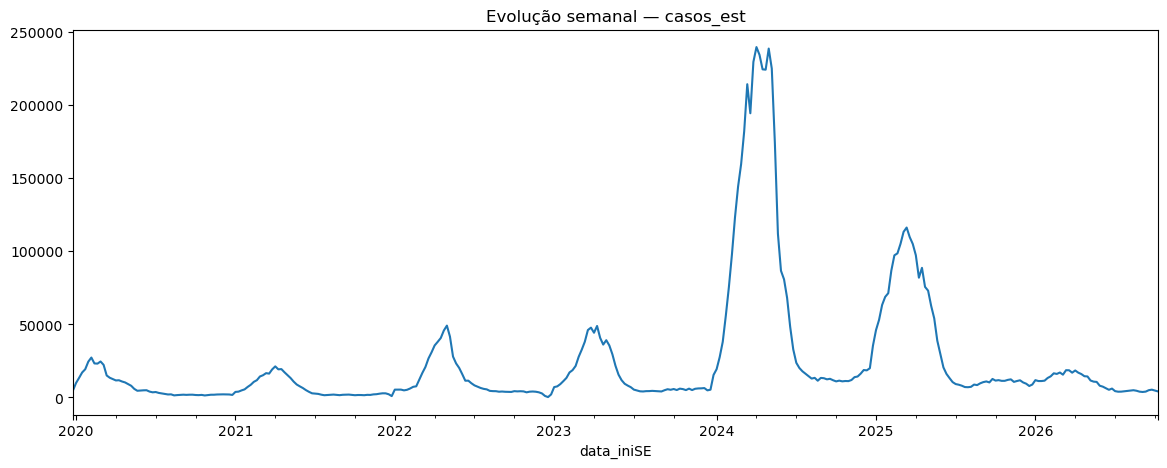

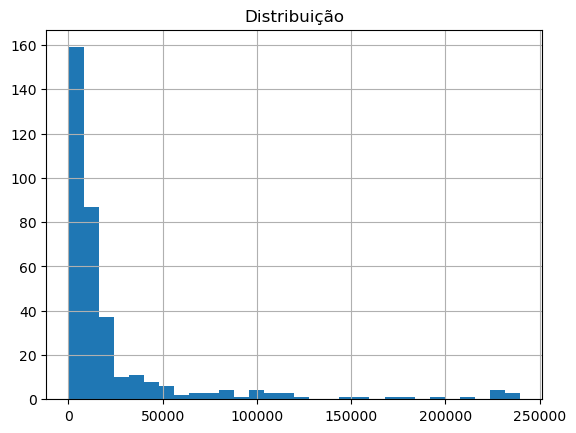

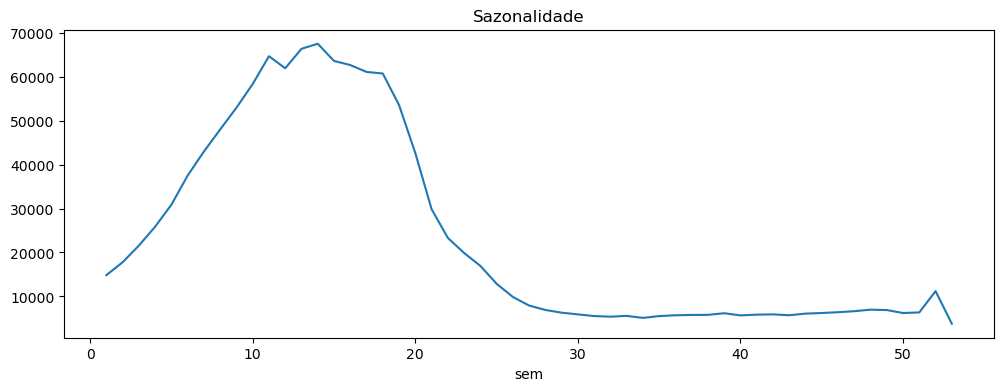

In [1]:
import io, requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor,as_completed
from tqdm.auto import tqdm
from IPython.display import display
ANO_INICIAL=2020; HOJE=pd.Timestamp.today().normalize(); CSV=Path("Base_Dengue_SP_2020_ate_hoje.csv")
IBGE="https://servicodados.ibge.gov.br/api/v1/localidades/municipios"; INFO="https://info.dengue.mat.br/api/alertcity"
def extrair():
 r=requests.get(IBGE,timeout=60); r.raise_for_status(); ms=[]
 for m in r.json():
  try:
   if m["microrregiao"]["mesorregiao"]["UF"]["sigla"]=="SP": ms.append((int(m["id"]),m["nome"]))
  except: pass
 def q(x):
  g,n=x; fs=[]
  for a in range(ANO_INICIAL,pd.Timestamp.today().year+1):
   try:
    p={"geocode":g,"disease":"dengue","format":"csv","ew_start":1,"ew_end":53,"ey_start":a,"ey_end":a}; z=requests.get(INFO,params=p,timeout=90)
    if z.status_code==200 and z.text.strip() and not z.text.startswith("[EE]"):
     d=pd.read_csv(io.StringIO(z.text)); d["geocode"],d["municipio_nome"],d["UF"]=g,n,"SP"; fs.append(d)
   except: pass
  return pd.concat(fs,ignore_index=True) if fs else None
 out=[]
 with ThreadPoolExecutor(max_workers=8) as ex:
  fut=[ex.submit(q,m) for m in ms]
  for f in tqdm(as_completed(fut),total=len(fut)): 
   d=f.result(); out.extend([d] if d is not None else [])
 if not out: raise RuntimeError("Sem dados do InfoDengue.")
 return pd.concat(out,ignore_index=True)
df0=pd.read_csv(CSV) if CSV.exists() else extrair()
if "data_ini_SE" in df0 and "data_iniSE" not in df0: df0=df0.rename(columns={"data_ini_SE":"data_iniSE"})
s=df0.data_iniSE.astype("string").str.strip(); dt=pd.to_datetime(s,format="%Y-%m-%d",errors="coerce"); m=dt.isna()&s.notna(); dt.loc[m]=pd.to_datetime(s.loc[m],format="%d/%m/%Y",errors="coerce")
df=df0.assign(data_iniSE=dt); df=df[df.data_iniSE.notna()&(df.data_iniSE<=HOJE)].copy(); df=df[df.UF.astype(str).str.upper().eq("SP")].copy() if "UF" in df else df
key=[c for c in ["geocode","data_iniSE"] if c in df]; df=df.drop_duplicates(key if len(key)==2 else None,keep="last").sort_values("data_iniSE")
if not CSV.exists(): df.to_csv(CSV,index=False,encoding="utf-8-sig",date_format="%Y-%m-%d")
print("Dimensão:",df.shape,"Período:",df.data_iniSE.min().date(),"a",df.data_iniSE.max().date()); display(pd.DataFrame({"nulos":df.isna().sum(),"%":(100*df.isna().mean()).round(2)}).sort_values("%",ascending=False))
TARGET="casos_est" if "casos_est" in df else "casos"; sums=[c for c in ["casos","casos_est"] if c in df]; means=[c for c in ["Rt","p_rt1","p_inc100k","tempmed","umidmed"] if c in df]
serie_sp=df.groupby("data_iniSE").agg({**{c:"sum" for c in sums},**{c:"mean" for c in means}}).sort_index(); serie_sp=serie_sp.reindex(pd.date_range(serie_sp.index.min(),serie_sp.index.max(),freq="W-SUN")); serie_sp.index.name="data_iniSE"
serie_modelo=serie_sp.copy(); serie_modelo[TARGET]=serie_modelo[TARGET].interpolate("time").ffill().bfill(); display(df[[c for c in [TARGET]+means if c in df]].describe().T)
serie_sp[TARGET].plot(figsize=(14,5),title=f"Evolução semanal — {TARGET}"); plt.show(); serie_sp[TARGET].dropna().hist(bins=30); plt.title("Distribuição"); plt.show(); serie_sp.assign(sem=serie_sp.index.isocalendar().week.astype(int)).groupby("sem")[TARGET].mean().plot(figsize=(12,4),title="Sazonalidade"); plt.show()


# **Modelos**

São comparados três métodos: **Seasonal Naive** de 52 semanas como referência; **SARIMA** como modelo estatístico sazonal; e **Random Forest** com lags, médias móveis e calendário. A divisão é cronológica (aprox. 70% treino, 15% validação e 15% teste). Para evitar vazamento, o Random Forest não usa variáveis contemporâneas derivadas dos próprios casos e as previsões de teste são recursivas, sem inserir valores reais futuros nos lags. O mesmo princípio é usado no baseline. As métricas são MAE, RMSE e MASE; valores menores indicam melhor desempenho.

,Modelo,MAE,RMSE,MASE,N_teste
0,Random Forest recursivo,3966.054,4515.644,0.166,54
1,Seasonal Naive,29640.333,43870.787,1.237,54
2,SARIMA,62370.266,92730.042,2.604,54


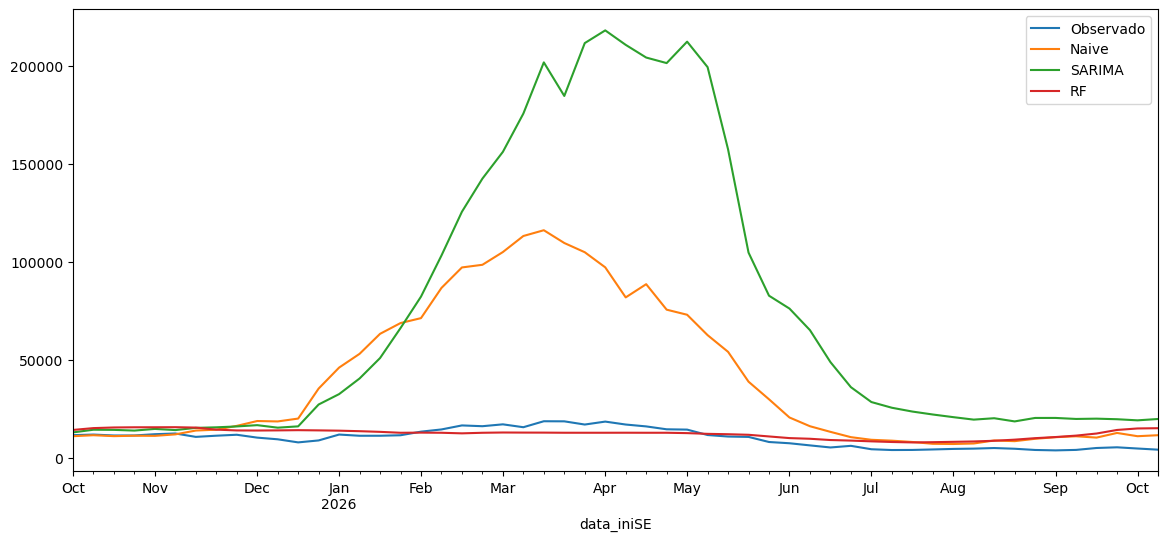

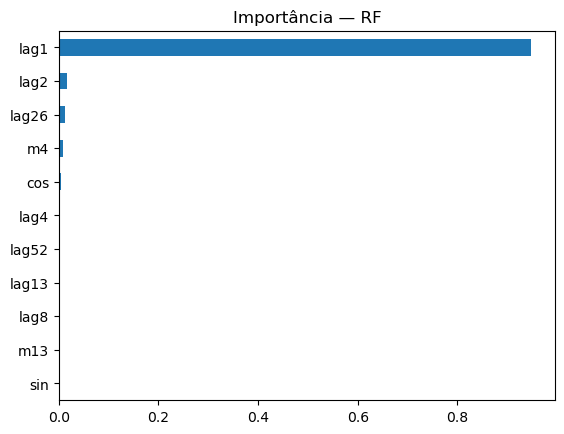

In [2]:
import warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX
from IPython.display import display
warnings.filterwarnings("ignore"); d=serie_modelo[[TARGET]].dropna(); n=len(d); a,b=int(n*.70),int(n*.85); train,valid,test=d.iloc[:a],d.iloc[a:b],d.iloc[b:]; tv=d.iloc[:b]
def mase(y,p,m=52): ins=tv[TARGET].to_numpy(); e=np.mean(np.abs(ins[m:]-ins[:-m])); return np.mean(np.abs(np.asarray(y)-np.asarray(p)))/e
def av(nome,y,p): return {"Modelo":nome,"MAE":mean_absolute_error(y,p),"RMSE":np.sqrt(mean_squared_error(y,p)),"MASE":mase(y,p),"N_teste":len(y)}
h=list(map(float,tv[TARGET])); o=[]
for _ in test.index: v=max(0.,h[-52]);o.append(v);h.append(v)
pn=pd.Series(o,index=test.index); rn=av("Seasonal Naive",test[TARGET],pn)
fit=SARIMAX(tv[TARGET],order=(1,1,1),seasonal_order=(1,1,0,52),enforce_stationarity=False,enforce_invertibility=False).fit(disp=False,maxiter=200); ps=fit.get_forecast(len(test)).predicted_mean.set_axis(test.index).clip(lower=0); rs=av("SARIMA",test[TARGET],ps)
L=[1,2,4,8,13,26,52]
def fx(s):
 x=pd.DataFrame({TARGET:s}); [x.__setitem__(f"lag{k}",x[TARGET].shift(k)) for k in L]; x["m4"]=x[TARGET].shift(1).rolling(4).mean(); x["m13"]=x[TARGET].shift(1).rolling(13).mean(); w=x.index.isocalendar().week.astype(int).to_numpy(); x["sin"],x["cos"]=np.sin(2*np.pi*w/52),np.cos(2*np.pi*w/52); return x.dropna()
def row(h,t): w=int(t.isocalendar().week); return {**{f"lag{k}":h[-k] for k in L},"m4":np.mean(h[-4:]),"m13":np.mean(h[-13:]),"sin":np.sin(2*np.pi*w/52),"cos":np.cos(2*np.pi*w/52)}
br=fx(tv[TARGET]); fs=[c for c in br if c!=TARGET]; rf=RandomForestRegressor(n_estimators=300,max_depth=10,min_samples_leaf=2,random_state=42,n_jobs=-1).fit(br[fs],br[TARGET]); h=list(map(float,tv[TARGET]));o=[]
for t in test.index: v=max(0.,float(rf.predict(pd.DataFrame([row(h,t)],columns=fs))[0]));o.append(v);h.append(v)
pr=pd.Series(o,index=test.index); rr=av("Random Forest recursivo",test[TARGET],pr); resultados=pd.DataFrame([rn,rs,rr]).sort_values("MAE").reset_index(drop=True); resultados[["MAE","RMSE","MASE"]]=resultados[["MAE","RMSE","MASE"]].round(3); display(resultados)
ax=test[TARGET].plot(figsize=(14,6),label="Observado"); pn.plot(ax=ax,label="Naive");ps.plot(ax=ax,label="SARIMA");pr.plot(ax=ax,label="RF");ax.legend();plt.show(); pd.Series(rf.feature_importances_,index=fs).sort_values().plot.barh(title="Importância — RF");plt.show()


# **Resultados**

A célula de modelagem gera a tabela comparativa de MAE, RMSE e MASE e o gráfico observado × previsto. As métricas não são fixadas no texto porque dependem da execução sobre a base atual. Após as correções metodológicas, as saídas antigas foram removidas e devem ser regeneradas com **Run All**.

## Cronograma atualizado

| Período | Atividade | Situação |
|---|---|---|
| 27/10–02/11 | Revisão dos modelos e base | Planejado |
| 03/11–09/11 | Análise crítica e hiperparâmetros | Planejado |
| 10/11–15/11 | Seleção do modelo final | Planejado |
| 16/11–20/11 | Melhorias e expansão | Planejado |
| 21/11–24/11 | Produto analítico | Planejado |
| 25/11–29/11 | Documentação e apresentação | Planejado |
| 30/11 | Entrega final | Planejado |

# **Dicussão e Conclusão**

A Etapa 3 estrutura um pipeline reproduzível de aquisição, preparação, EDA e modelagem para dengue em São Paulo. O recorte estadual permite uma prova de conceito semanal sem descartar a base municipal. A divisão cronológica e as previsões recursivas reduzem o risco de vazamento de informação. A comparação entre baseline sazonal, SARIMA e Random Forest deve considerar MAE, RMSE, MASE, comportamento nos picos, interpretabilidade e estabilidade.

As principais limitações são a agregação estadual, possíveis revisões retrospectivas do InfoDengue, dados ausentes e heterogeneidade entre municípios. Na Etapa 4, recomenda-se refinar hiperparâmetros, testar variáveis climáticas defasadas ou regressoras exógenas disponíveis no instante da previsão, aplicar validação temporal em múltiplas janelas e avaliar granularidade municipal/regional.

# **Apresentação**

**Link do vídeo:** _a inserir na entrega final_

# **Referências**

BOX, G. E. P.; JENKINS, G. M. *Time Series Analysis: Forecasting and Control*. San Francisco: Holden-Day, 1976.

HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts, 2021.

INFODENGUE. **API: acesso aos dados epidemiológicos**. Disponível em: <https://info.dengue.mat.br>. Acesso em: 20 ago. 2026.

INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE). **API de localidades**. Disponível em: <https://servicodados.ibge.gov.br/api/docs/localidades>. Acesso em: 26 out. 2026.

RUMELHART, D. E. et al. Learning representations by back-propagating errors. *Nature*, v. 323, p. 533–536, 1986.

ZHANG, G. P. Time series forecasting using a hybrid ARIMA and neural network model. *Neurocomputing*, v. 50, p. 159–175, 2003.